In [7]:
import os
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score

# if the dataset isn't available download and save it as file
if not os.path.exists("mnist.npz"):
    from sklearn.datasets import fetch_openml
    import numpy as np

    mnist = fetch_openml("mnist_784", version=1, as_frame=False) # return pd DataFrame by default

    X = mnist.data
    y = mnist.target

    np.savez_compressed("mnist.npz", X=X, y=y, allow_pickle=True)
    print("Dataset downloaded and saved.")
else:
    print("Dataset already exist.")

Dataset already exist.


In [8]:
with np.load("mnist.npz", allow_pickle=True) as data:
    print(data.files)
    print(data["X"].shape)
    print(data["y"].shape)

    x = data["X"]
    y = data["y"]


['X', 'y']
(70000, 784)
(70000,)


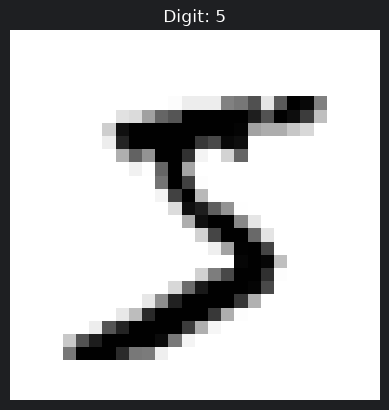

In [9]:
# Plot the first image
import matplotlib.pyplot as plt

data = np.load("mnist.npz", allow_pickle=True)
plt.imshow(x[0].reshape(28, 28), cmap="binary")
plt.title(f"Digit: {y[0]}")
plt.axis("off")
plt.show()

### Separate training and test set. We split it like this (0-60k, 60k-70k) only because the dataset is already shuffled for us. If not, that test set would not be good representation of reality.

In [10]:
X_train, X_test = x[:60000], x[60000:]
y_train, y_test = y[:60000], y[60000:]


print(y[:5])
print(x[:5])

['5' '0' '4' '1' '9']
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


## Training a Binary Classifier
Train the model to be a 5 detector. It distingushes between 5 and non-5

In [11]:
y_train = y_train.astype(np.uint8)
y_test = y_test.astype(np.uint8)

y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

# Pick a classifier Algorithm. Start with Stochastic Gradient Descent classifier

from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

sgd_clf.predict(X_test)

array([False, False, False, ..., False,  True, False], shape=(10000,))

## Performance Measure
When training a model what we actually care about is how the model perform on data it never seen. This ability is called generalization. Finding the true general signal from the noisy observation. Evaluating classifier's performance is trickier than evaluating regressor.

In [6]:
# Use k-fold cross validation

from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")  # 3 fold

array([0.95035, 0.96035, 0.9604 ])

### Nice, above 95% accuracy!

But don't be excited. The mnist data set is skewed (only about 9% of the data is 5) hence a model that learn nothing and predict a number is non-5 every time will have 91% accuracy.

Or to make it clear if there are 99% healthy people, the model then predict everyone as healthy it achieves 99% accuracy.

**Is this model useful?** No. Hence accuracy gives us a false sense being good.

---

### Let's use Dummy Classifier,

Dummy will just give prediction for most frequent data. In our case non-5, so everytime it predicts non-5.

In [14]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))

# Check Dummy classifier accuracy

cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")


False


array([0.90965, 0.90965, 0.90965])

Above 90% accurate, that's because about 90% of the data is non-5. This demonstrates why accuracy is not preferred performance measure for classifier specially when we are dealign with a skewed data. A better way is looking at Confusion Matrix.

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)
print(cm)


[[53892   687]
 [ 1891  3530]]


Great, Refer about confusion matrix. The row is the actual class and the columns are the predicted values. A perfect model would have non zero value in diagonal only. From the confusion matric we can a lot of information, accuracy, precision, recall...

In [17]:
# Example for perfect model

y_train_5_perfection = y_train_5
cm = confusion_matrix(y_train_5, y_train_5_perfection)
print(cm)

[[54579     0]
 [    0  5421]]


## Precision and Recall

In [19]:
from sklearn.metrics import precision_score, recall_score
print(precision_score(y_train_5, y_train_pred))
recall_score(y_train_5, y_train_pred)

0.8370879772350012


0.6511713705958311

### F1_score

In [20]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7325171197343847